/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


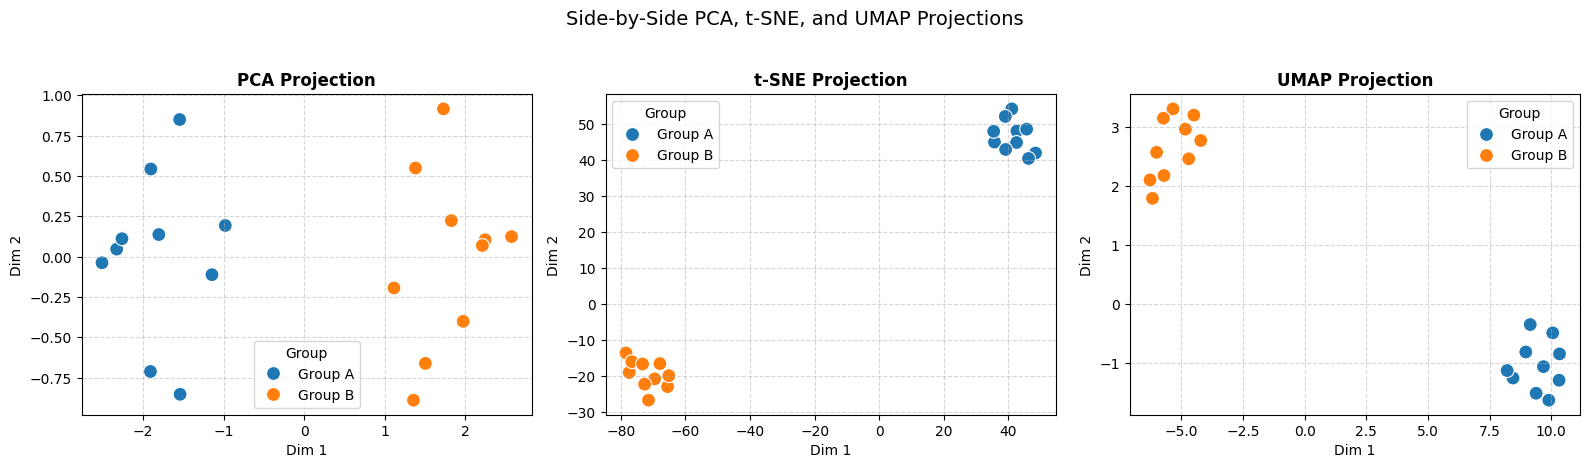

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# --- DATASET GENERATION ---
np.random.seed(42)
data = np.random.randn(20, 4)
data[10:, :] += 3.5  # Create 2 groups
labels = ['Group A'] * 10 + ['Group B'] * 10
df = pd.DataFrame(data, columns=['F1', 'F2', 'F3', 'F4'])

# FIX 1: Properly scale the dataset using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# PCA
pca_res = PCA(n_components=2).fit_transform(X_scaled)

# FIX 2: Lower perplexity so it is less than n_samples (20)
tsne_res = TSNE(n_components=2, perplexity=5, random_state=42).fit_transform(X_scaled)

# UMAP
umap_res = umap.UMAP(n_components=2, n_neighbors=5, random_state=42).fit_transform(X_scaled)

# --- PLOTTING ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
results = [('PCA', pca_res), ('t-SNE', tsne_res), ('UMAP', umap_res)]

for ax, (title, res_data) in zip(axes, results):
    plot_df = pd.DataFrame(res_data, columns=['Dim 1', 'Dim 2'])
    # FIX 3: Add group labels and pass hue='Group' to separate Group A and B
    plot_df['Group'] = labels
    sns.scatterplot(
        data=plot_df,
        x='Dim 1',
        y='Dim 2',
        hue='Group',
        palette=['#1f77b4', '#ff7f0e'],
        ax=ax,
        s=100
    )
    ax.set_title(f"{title} Projection", fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Side-by-Side PCA, t-SNE, and UMAP Projections", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

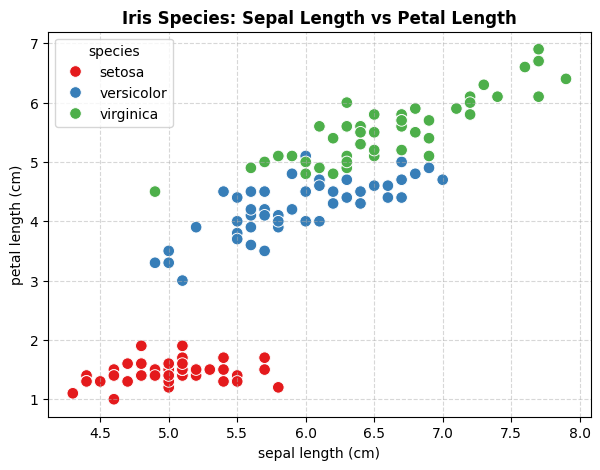

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


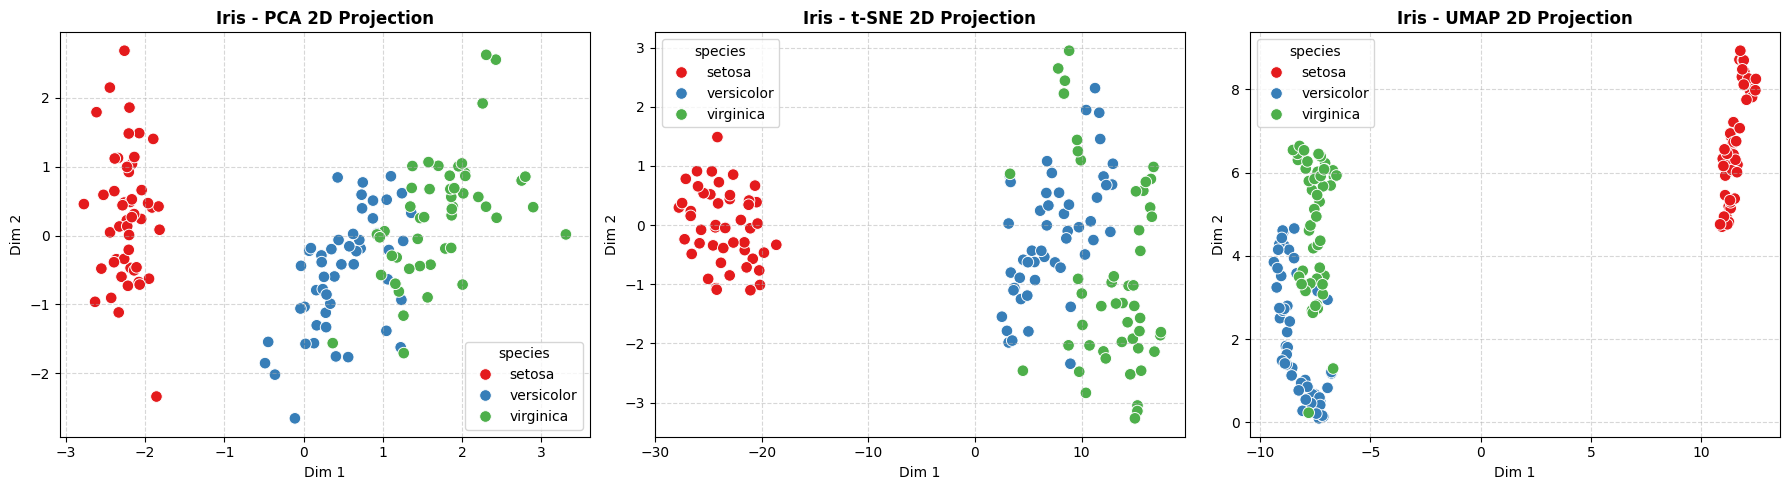

In [4]:
from sklearn.datasets import load_iris

iris = load_iris()
iris_df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
iris_df['species'] = iris.target_names[iris.target]

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=iris_df,
    x='sepal length (cm)',
    y='petal length (cm)',
    hue='species',
    palette='Set1',
    s=70
)
plt.title("Iris Species: Sepal Length vs Petal Length", fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

X_iris = iris_df.drop(columns=['species'])
X_iris_scaled = StandardScaler().fit_transform(X_iris)

pca_iris = PCA(n_components=2).fit_transform(X_iris_scaled)
tsne_iris = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_iris_scaled)
umap_iris = umap.UMAP(n_components=2, n_neighbors=15, random_state=42).fit_transform(X_iris_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
iris_results = [('PCA', pca_iris), ('t-SNE', tsne_iris), ('UMAP', umap_iris)]

for ax, (title, res_data) in zip(axes, iris_results):
    res_df = pd.DataFrame(res_data, columns=['Dim 1', 'Dim 2'])
    res_df['species'] = iris_df['species']

    sns.scatterplot(
        data=res_df,
        x='Dim 1',
        y='Dim 2',
        hue='species',
        palette='Set1',
        ax=ax,
        s=70
    )
    ax.set_title(f"Iris - {title} 2D Projection", fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()